# Function 1 — Week 7: a simple source-shaped model

Compare a small Gaussian positive-source hypothesis with the existing fits using **only the owner's 16 official observations through round 6**. Peer discussion motivates testing this model class; no peer coordinates, outputs or fitted parameters enter training, subset selection, bounds or the query calculation. The held-out GP forecasts below are the preserved **official-only** forecasts.

The latest return at `(0.537942, 0.522217)` is `2.1709129251221444e-14`. It is a numerical best but remains practically zero; no physical detection threshold is established. Seven queries remain including Week 7. This notebook recommends an experiment for discussion and performs no course evaluation or submission.

[Reading report](../source-shape.md) · [Previous signed/magnitude study](activity_hypothesis.ipynb) · [Week-level review](../report.md)


In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone

root = next(p for p in Path.cwd().parents if (p / "run-python.ps1").is_file())
expected = root / ".venv/Scripts/python.exe"
if Path(sys.executable).resolve() != expected.resolve():
    raise RuntimeError(f"Use the capstone-local interpreter: {expected}")
shared = root / "stage-2-bbo/notebooks/Shared"
function_shared = shared.parent / "Function_1/FunctionSpecificShared"
for folder in (shared, function_shared):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from function_1_source_helpers import (fit_gaussian_source, predict_source_log10, source_peak,
    source_target_predictions, source_leave_one_out, leave_one_out_baselines)
from function_1_model_helpers import signed_log
from function_1_activity_helpers import activity_targets
from exploration_review_helpers import load_exploration_review
from model_helpers import make_models, finish_figure
from model_review_helpers import make_regression_models, score_review_candidates
from model_review_plots import plot_held_out_comparison
from prediction_review_helpers import make_candidate_review
from query_budget import remaining_queries
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
FUNCTION = 1
WEEK = 7
STUDY_DATE = "2026-11-05"
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
ACTIVITY_PATH = ANALYSIS_DIR / "activity-hypothesis/results.json"
MODEL_PATH = ANALYSIS_DIR / "model-review.json"
OUTPUT_DIR = ANALYSIS_DIR / "source-shape"
INPUT_COLUMNS = ["x1", "x2"]
HEIGHT_SCALE = 1e-200
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1}
POSITIVE_COUNTS = (5, 6, 7, 8, 9)
DEFAULT_MODEL = "Positive source: circular, top 5"
MINIMUM_CURVATURE = 1e-8
PRECISION = 6
WEIGHT = 1.96
# The four-parameter default uses five positive readings: one residual degree of freedom.
# The axis-aligned five-parameter version and larger subsets are sensitivity controls.
specifications = {}
for count in POSITIVE_COUNTS:
    for anisotropic in (False, True):
        label = f"Positive source: {'axis-aligned' if anisotropic else 'circular'}, top {count}"
        specifications[label] = dict(positive_only=True, positive_count=count,
            anisotropic=anisotropic, minimum_curvature=MINIMUM_CURVATURE)
for anisotropic in (False, True):
    label = f"All-magnitude envelope: {'axis-aligned' if anisotropic else 'circular'}"
    specifications[label] = dict(positive_only=False, positive_count=None,
        anisotropic=anisotropic, minimum_curvature=MINIMUM_CURVATURE)


## Source hypothesis and its limitations

The circular positive source has four parameters:

$$
s(x)=A\exp\left[-\frac{(x_1-c_1)^2+(x_2-c_2)^2}{2\sigma^2}\right],\quad A>0,\;\sigma>0.
$$

Taking base-10 logs gives a concave quadratic:

$$
\ell(x)=\log_{10}s(x)=a+b_1x_1+b_2x_2-q(x_1^2+x_2^2),\quad q>0.
$$

Its centre is $c_i=b_i/(2q)$ and $\sigma=(2q\ln 10)^{-1/2}$. The axis-aligned control allows separate positive curvatures $q_1,q_2$. A bounded linear least-squares fit estimates the coefficients; no initial guess near a reported source is needed. The permitted fitted maximum is computed analytically and rounded to six decimals.

The default fits the strongest **five positive training readings**. This explicitly assumes they describe one dominant positive component. Negative readings remain in the dataset and every held-out evaluation; they are excluded only from fitting that component. This model cannot describe their signs or the entire function. Controls fit 6–9 positives and all absolute magnitudes. The default is not selected for proximity to the cohort's location, and no location is supplied to fitting.

Every leave-one-out fold reselects its positive training subset after removing the held-out observation. Evaluation uses all 16 official targets. A five-point axis-aligned fit has zero residual degrees of freedom; its interpolation is not independent evidence of accuracy. Model class and subset strategy were introduced after seeing these data and peer discussion, so validation remains retrospective.


In [3]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
review = load_exploration_review(DATA_PATH, input_columns=INPUT_COLUMNS,
    expected_round_counts=EXPECTED_ROUND_COUNTS)
official = review["data"]
inputs = official[INPUT_COLUMNS].to_numpy()
raw = official.y.to_numpy()
targets = {**activity_targets(raw, scale=HEIGHT_SCALE), "raw_signed": raw.copy(),
           "log10_magnitude": np.log10(np.abs(raw))}
assert len(official) == 16 and not official.observation_id.str.startswith("peer-").any()
assert raw[-1] == 2.1709129251221444e-14 and np.count_nonzero(raw > 0) == 9
prior = json.loads(ACTIVITY_PATH.read_text(encoding="utf-8"))
assert prior["official_rows"] == len(official)
assert prior["source_sha256"][DATA_PATH.relative_to(root).as_posix()] == sha(DATA_PATH)
# Extract only official-only GP forecasts. No peer-assisted forecast or peer CSV is used.
gp_names = prior["settings"]["gp_names"]
official_gp_predictions = {name: {model: np.asarray(values) for model, values in
    prior["held_out_predictions"][name]["official"].items() if model in gp_names}
    for name in ("signed", "magnitude", "raw_magnitude")}
original = json.loads(MODEL_PATH.read_text(encoding="utf-8"))
assert original["official_observations"] == len(official) and original["height_scale"] == HEIGHT_SCALE
assert original["snapshot_sha256"] == sha(DATA_PATH)
neural_architecture = original["selected_neural_architecture"]
neural_names = [f"NN {neural_architecture} seed {seed}" for seed in original["neural_seeds"]]
neural_predictions = np.mean([original["held_out_predictions"][name] for name in neural_names], axis=0)
fixed_settings, adaptive_settings = prior["settings"]["fixed"], prior["settings"]["adaptive"]
search_settings = prior["settings"]["search"]
sources = [DATA_PATH, ACTIVITY_PATH, MODEL_PATH, function_shared / "function_1_source_helpers.py",
    function_shared / "function_1_model_helpers.py", function_shared / "function_1_activity_helpers.py",
    *[shared / f"{name}.py" for name in ("model_helpers", "model_review_helpers", "prediction_review_helpers")]]
source_before = {p.relative_to(root).as_posix(): sha(p) for p in sources}
submission_paths = sorted((root / "stage-2-bbo/submissions").glob("Week_*/submissions.txt"))
submission_before = {p.relative_to(root).as_posix(): sha(p) for p in submission_paths}
OUTPUT_DIR.mkdir(exist_ok=True)
display(official.style.format({"x1": "{:.6f}", "x2": "{:.6f}", "y": "{:.12e}"}))
print("Official rows:", len(official), "Positive:", int((raw > 0).sum()), "Negative:", int((raw < 0).sum()))
print("Peer training rows: 0; query opportunities:", remaining_queries(WEEK_DIR))


,observation_id,source_round,x1,x2,y
0,initial-001,0,0.319404,0.762959,1.322677039545e-79
1,initial-002,0,0.574329,0.879898,1.033078237523e-46
2,initial-003,0,0.731024,0.733000,7.710875114503e-16
3,initial-004,0,0.840353,0.264732,3.341771007676e-124
4,initial-005,0,0.650114,0.681526,-3.606062644363e-03
5,initial-006,0,0.410437,0.147554,-2.159249035733e-54
6,initial-007,0,0.312691,0.078723,-2.089093270232e-91
7,initial-008,0,0.683418,0.861057,2.535001153558e-40
8,initial-009,0,0.082507,0.403488,3.606771190142e-81
9,initial-010,0,0.883890,0.582254,6.229856468169e-48


Official rows: 16 Positive: 9 Negative: 7
Peer training rows: 0; query opportunities: 7


In [4]:
def mae(actual, predicted):
    return float(np.mean(np.abs(actual-predicted))) if np.isfinite(predicted).all() else None

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual-predicted)**2))) if np.isfinite(predicted).all() else None

runs, prediction_sets, source_rows = {}, {}, []
for name, settings in specifications.items():
    run = source_leave_one_out(inputs, raw, **settings)
    runs[name] = run
    predicted = source_target_predictions(run["log10_predictions"], height_scale=HEIGHT_SCALE)
    prediction_sets[name] = predicted
    fit, peak = run["fit"], run["peak"]
    row = {"Model": name, "Selected readings": fit["selected_count"],
        "Residual df": fit["residual_degrees_of_freedom"],
        "Signed h MAE": mae(targets["signed"], predicted["signed"]),
        "Signed h RMSE": rmse(targets["signed"], predicted["signed"]),
        "Log magnitude g MAE": mae(targets["magnitude"], predicted["magnitude"]),
        "Log magnitude g RMSE": rmse(targets["magnitude"], predicted["magnitude"]),
        "Raw |y| MAE": mae(targets["raw_magnitude"], predicted["raw_magnitude"]),
        "Raw signed y MAE": mae(raw, predicted["raw_signed"]),
        "Training log10 MAE": fit["training_log10_mae"],
        "Peak input": peak["portal_input"], "Predicted peak height": peak["predicted_height"],
        "Curvature at floor": fit["curvature_at_floor"]}
    source_rows.append(row)
source_table = pd.DataFrame(source_rows)
display(source_table.style.format(precision=6))
baseline_predictions = {target: leave_one_out_baselines(values) for target, values in targets.items()}
baseline_rows = [{"Benchmark": name, **{target: mae(values, baseline_predictions[target][name])
                 for target, values in targets.items()}} for name in ("mean", "median")]
display(pd.DataFrame(baseline_rows))
gp_rows, gp_best = [], {}
for target_name, predictions in official_gp_predictions.items():
    errors = {name: mae(targets[target_name], values) for name, values in predictions.items()}
    best = min(errors, key=errors.get)
    gp_best[target_name] = dict(name=best, mae=errors[best], training_scope="official")
    gp_rows.extend({"Target": target_name, "GP": name, "Official LOO MAE": error,
        "Official LOO RMSE": rmse(targets[target_name], predictions[name])} for name, error in errors.items())
display(pd.DataFrame(gp_rows))
print("Best official-only GPs:", json.dumps(gp_best, indent=2))
signed_comparison = []
for name, predicted in {
    "Mean baseline": baseline_predictions["signed"]["mean"],
    "Median baseline": baseline_predictions["signed"]["median"],
    "Best official-only GP": official_gp_predictions["signed"][gp_best["signed"]["name"]],
    f"Neural seed mean: {neural_architecture}": neural_predictions,
    DEFAULT_MODEL: prediction_sets[DEFAULT_MODEL]["signed"],
}.items():
    signed_comparison.append(dict(model=name, official_rows=len(raw),
        signed_h_mae=mae(targets["signed"], predicted), signed_h_rmse=rmse(targets["signed"], predicted)))
assert np.isclose(signed_comparison[-2]["signed_h_mae"], original["neural_ensemble_errors"]["LOO MAE"])
display(pd.DataFrame(signed_comparison))


,Model,Selected readings,Residual df,Signed h MAE,Signed h RMSE,Log magnitude g MAE,Log magnitude g RMSE,Raw |y| MAE,Raw signed y MAE,Training log10 MAE,Peak input,Predicted peak height,Curvature at floor
0,"Positive source: circular, top 5",5,1,91.661687,155.153808,33.275888,59.599443,0.000361,0.000811,0.061325,0.627916-0.628953,0.708088,False
1,"Positive source: axis-aligned, top 5",5,0,92.202792,155.321922,33.618074,59.199966,0.000385,0.000755,0.000000,0.629738-0.627069,0.613608,False
2,"Positive source: circular, top 6",6,2,102.955042,156.733711,44.649405,63.716438,2700822923398929408.000000,2700822923398929408.000000,0.055620,0.628011-0.629003,0.748625,False
3,"Positive source: axis-aligned, top 6",6,1,105.868509,157.998750,47.424568,66.489608,183435316528166152679515882853972836352.000000,183435316528166152679515882853972836352.000000,0.045404,0.628031-0.628707,0.662531,False
4,"Positive source: circular, top 7",7,3,147.717550,190.451734,43.389344,58.748594,0.000570,0.000570,11.353926,0.645271-0.489663,0.000000,False
5,"Positive source: axis-aligned, top 7",7,2,170.010301,215.791327,63.982986,85.165793,283133395820491312194645062057984.000000,283133395820491312194645062057984.000000,8.724972,0.631809-0.000000,9095064324049307050326647832183554074214400.000000,True
6,"Positive source: circular, top 8",8,4,123.582822,171.649633,37.146033,46.414235,0.000570,0.000570,18.063353,0.528212-0.629452,0.000000,False
7,"Positive source: axis-aligned, top 8",8,3,113.122803,162.418987,49.577173,63.952008,0.000570,0.000570,14.591177,0.569795-0.634869,0.000000,False
8,"Positive source: circular, top 9",9,5,120.533740,169.185329,38.746558,48.545158,0.000570,0.000570,17.146930,0.518161-0.628175,0.000000,False
9,"Positive source: axis-aligned, top 9",9,4,117.530272,166.016515,44.944545,56.850840,0.000570,0.000570,13.767667,0.561203-0.634347,0.000000,False


,Benchmark,signed,magnitude,raw_magnitude,raw_signed,log10_magnitude
0,mean,135.523206,48.422875,0.001063,0.001063,48.434747
1,median,165.078410,58.002869,0.000570,0.000570,58.014000


,Target,GP,Official LOO MAE,Official LOO RMSE
0,signed,GP: local (l=0.15),205.786113,279.985362
1,signed,GP: broad (l=0.35),195.924267,246.374169
2,signed,Gaussian process,135.651902,147.135264
3,signed,GP: separate length scales,143.992843,159.799443
4,magnitude,GP: local (l=0.15),26.631361,42.067521
5,magnitude,GP: broad (l=0.35),21.556723,29.174468
6,magnitude,Gaussian process,22.339317,35.138313
7,magnitude,GP: separate length scales,24.989488,36.628727
8,raw_magnitude,GP: local (l=0.15),0.002197,0.003105
9,raw_magnitude,GP: broad (l=0.35),0.001949,0.002644


Best official-only GPs: {
  "signed": {
    "name": "Gaussian process",
    "mae": 135.6519019929571,
    "training_scope": "official"
  },
  "magnitude": {
    "name": "GP: broad (l=0.35)",
    "mae": 21.556723032387445,
    "training_scope": "official"
  },
  "raw_magnitude": {
    "name": "Gaussian process",
    "mae": 0.001064941636201738,
    "training_scope": "official"
  }
}


,model,official_rows,signed_h_mae,signed_h_rmse
0,Mean baseline,16,135.523206,146.949715
1,Median baseline,16,165.078410,174.736317
2,Best official-only GP,16,135.651902,147.135264
3,Neural seed mean: relu-8-8,16,193.057461,234.137157
4,"Positive source: circular, top 5",16,91.661687,155.153808


## Compare identical held-out targets

The signed-log score $h$, log-magnitude $g$ and raw magnitude $|y|$ have different units. Compare each model with its own target-specific benchmarks; raw MAEs across columns do not measure the same task. The source also has a raw signed error because it predicts a positive response directly. An inverse-transformed GP posterior mean is not claimed as an expected raw score.

Every row contributes to the global metrics, including all seven negative returns and weaker positives excluded from positive-source training. The source's in-subset training error is shown separately and must not be treated as validation. Plot annotations below give RMSE as a secondary diagnostic; model comparisons retain the declared MAE criterion. The source reduces signed-log MAE but has **higher signed-log RMSE** than the official-only GP: its large mistakes still matter. The saved neural seed-mean forecasts use the same official targets and no peer training; they are read without retraining.


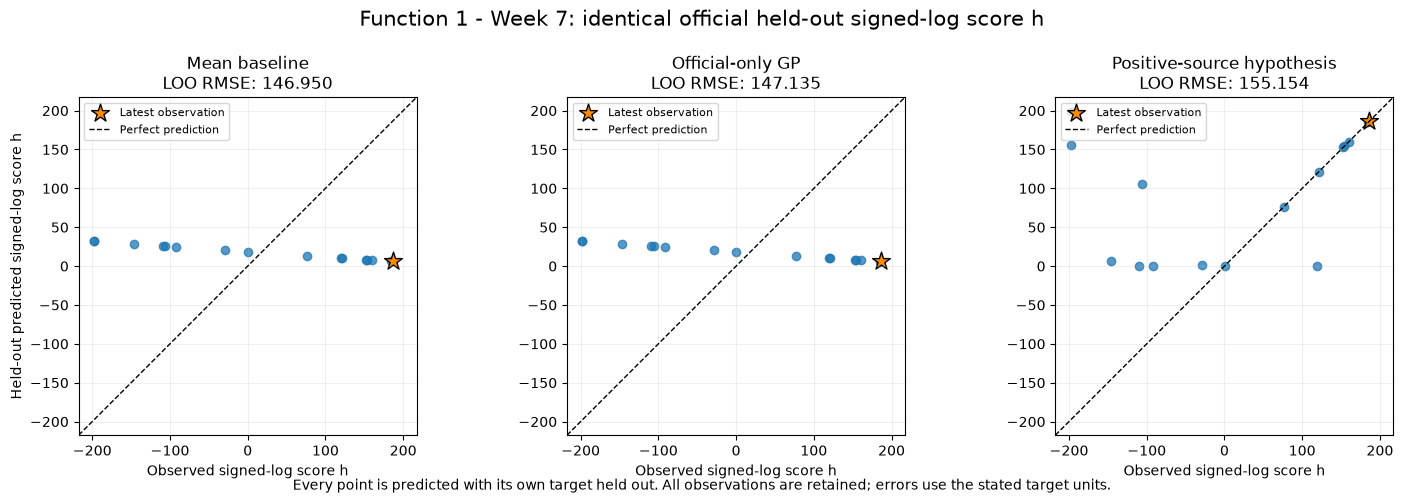

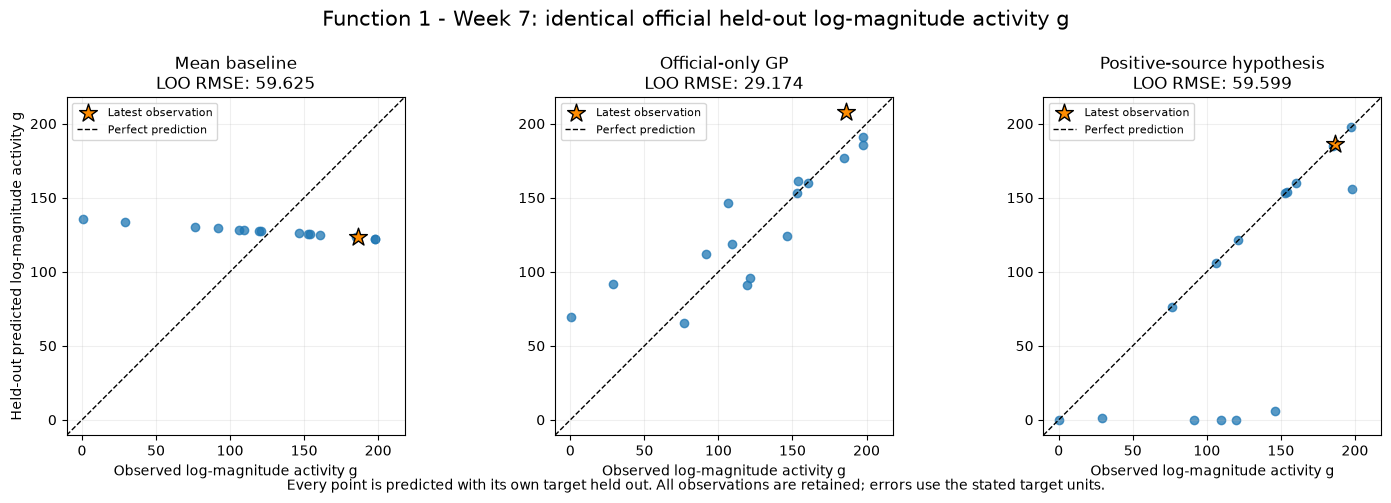

,observation_id,source_round,x1,x2,y,observed_log10_abs_y,source_loo_log10,source_loo_h,source_h_absolute_error,gp_h_absolute_error
0,initial-001,0,0.319404,0.762959,1.322677040e-79,-78.878546,-78.760395,121.239605,0.118,110.634
1,initial-002,0,0.574329,0.879898,1.033078238e-46,-45.985867,-45.879995,154.120005,0.106,145.553
2,initial-003,0,0.731024,0.733000,7.710875115e-16,-15.112896,-14.970830,185.029170,0.142,179.865
3,initial-004,0,0.840353,0.264732,3.341771008e-124,-123.476023,-123.679950,76.320050,0.204,63.064
4,initial-005,0,0.650114,0.681526,-3.606062644e-03,-2.442967,-2.412771,197.587229,395.144,230.206
5,initial-006,0,0.410437,0.147554,-2.159249036e-54,-53.665697,-194.034072,5.965928,152.300,174.603
6,initial-007,0,0.312691,0.078723,-2.089093270e-91,-90.680042,-279.551520,0.000000,109.320,135.109
7,initial-008,0,0.683418,0.861057,2.535001154e-40,-39.596022,-39.812475,160.187525,0.216,152.370
8,initial-009,0,0.082507,0.403488,3.606771190e-81,-80.442881,-242.160130,0.000000,119.557,108.966
9,initial-010,0,0.883890,0.582254,6.229856468e-48,-47.205522,-46.555931,153.444069,0.650,144.419


In [5]:
default = runs[DEFAULT_MODEL]
default_predictions = prediction_sets[DEFAULT_MODEL]
for target, label in (("signed", "signed-log score h"), ("magnitude", "log-magnitude activity g")):
    selected_gp = gp_best[target]["name"]
    display(plot_held_out_comparison(
        {"Mean baseline": baseline_predictions[target]["mean"],
         "Official-only GP": official_gp_predictions[target][selected_gp],
         "Positive-source hypothesis": default_predictions[target]}, targets[target],
        model_names=["Mean baseline", "Official-only GP", "Positive-source hypothesis"],
        latest_mask=review["latest_mask"], target_label=label,
        title=f"Function 1 - Week 7: identical official held-out {label}",
        save_to=OUTPUT_DIR / f"{target}-held-out-comparison.png"))
residual_table = official[["observation_id", "source_round", *INPUT_COLUMNS, "y"]].copy()
residual_table["observed_log10_abs_y"] = targets["log10_magnitude"]
residual_table["source_loo_log10"] = default["log10_predictions"]
residual_table["source_loo_h"] = default_predictions["signed"]
residual_table["source_h_absolute_error"] = np.abs(targets["signed"]-default_predictions["signed"])
residual_table["gp_h_absolute_error"] = np.abs(targets["signed"]-official_gp_predictions["signed"][gp_best["signed"]["name"]])
display(residual_table.style.format({"y":"{:.9e}", "source_h_absolute_error":"{:.3f}", "gp_h_absolute_error":"{:.3f}"}))


## Source geometry and sensitivity

The maps show assumed fitted shapes, not measured terrain. The training subset is marked separately from other official readings. The fitted circular peak is an analytic maximum under that hypothesis; no reported cohort location or external optimum is drawn on these figures.

Changing the retained count tests the assumption of a single dominant positive component. Weak readings can belong to another structure or expose model misspecification; they are not automatically labelled noise. Curvature at its floor, boundary maxima and very large extrapolated peaks are explicit warnings against that fit.


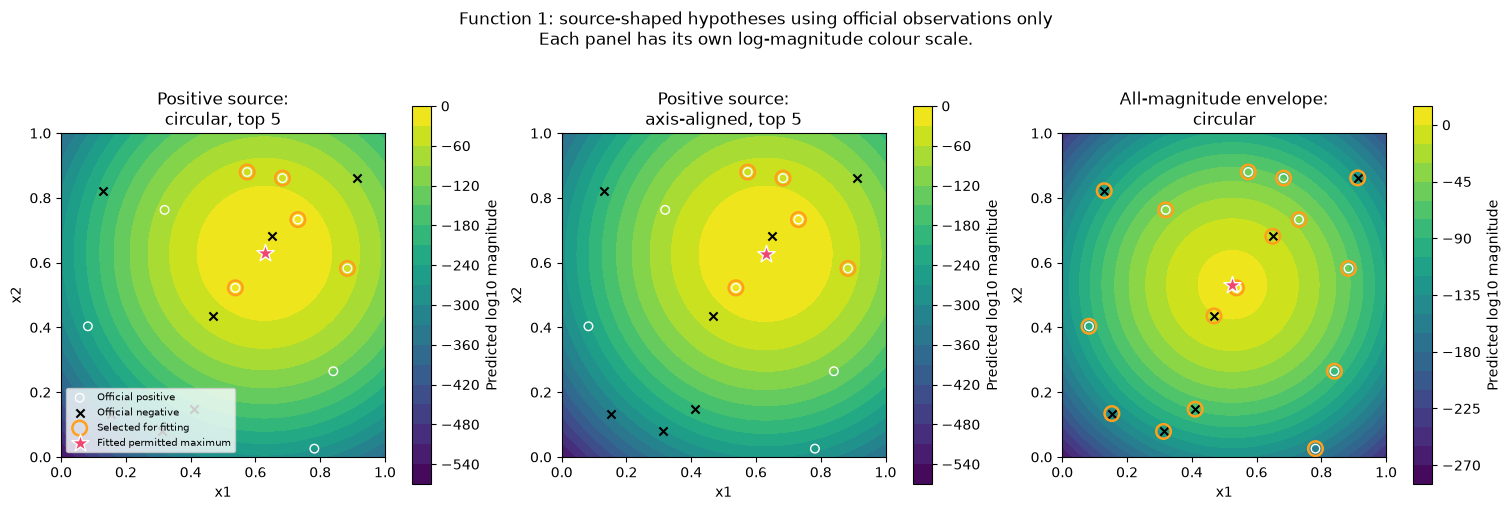

,model,point,portal_input,predicted_log10_height,predicted_height,stationary_point_inside_domain,curvature_at_floor,sigma,training_ids
0,"Positive source: circular, top 5","[0.627916, 0.628953]",0.627916-0.628953,-0.149913,7.080881e-01,True,False,"[0.017678294379784333, 0.017678294379784333]","[round-06, initial-003, initial-008, initial-0..."
1,"Positive source: axis-aligned, top 5","[0.629738, 0.627069]",0.629738-0.627069,-0.212109,6.136084e-01,True,False,"[0.017533846623861142, 0.017841665629913496]","[round-06, initial-003, initial-008, initial-0..."
2,"Positive source: circular, top 6","[0.628011, 0.629003]",0.628011-0.629003,-0.125736,7.486247e-01,True,False,"[0.017667312054378277, 0.017667312054378277]","[round-06, initial-003, initial-008, initial-0..."
3,"Positive source: axis-aligned, top 6","[0.628031, 0.628707]",0.628031-0.628707,-0.178794,6.625313e-01,True,False,"[0.017672339284878356, 0.017705655245774058]","[round-06, initial-003, initial-008, initial-0..."
4,"Positive source: circular, top 7","[0.645271, 0.489663]",0.645271-0.489663,-15.781273,1.654729e-16,True,False,"[0.03125136094996759, 0.03125136094996759]","[round-06, initial-003, initial-008, initial-0..."
5,"Positive source: axis-aligned, top 7","[0.631809, 0.0]",0.631809-0.000000,42.958806,9.095064e+42,False,True,"[0.02694274171889682, 4659.906017846561]","[round-06, initial-003, initial-008, initial-0..."
6,"Positive source: circular, top 8","[0.528212, 0.629452]",0.528212-0.629452,-18.693369,2.025961e-19,True,False,"[0.02540638070927059, 0.02540638070927059]","[round-06, initial-003, initial-008, initial-0..."
7,"Positive source: axis-aligned, top 8","[0.569795, 0.634869]",0.569795-0.634869,-17.666268,2.156415e-18,True,False,"[0.03344256941270838, 0.01913148511195036]","[round-06, initial-003, initial-008, initial-0..."
8,"Positive source: circular, top 9","[0.518161, 0.628175]",0.518161-0.628175,-11.614466,2.429596e-12,True,False,"[0.02303443051266163, 0.02303443051266163]","[round-06, initial-003, initial-008, initial-0..."
9,"Positive source: axis-aligned, top 9","[0.561203, 0.634347]",0.561203-0.634347,-21.211024,6.151429e-22,True,False,"[0.031956339753876545, 0.021557879007016188]","[round-06, initial-003, initial-008, initial-0..."


min_point         [0.627916, 0.628253]
max_point          [0.62891, 0.629387]
median_point      [0.627916, 0.628953]
min_height                    0.438816
max_height                    0.877263
boundary_folds                       0
dtype: object

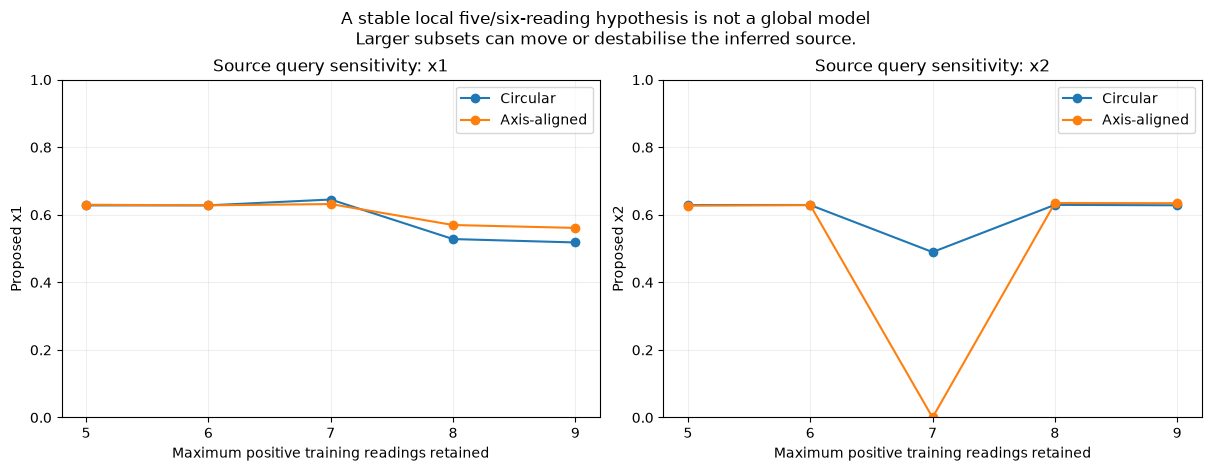

In [6]:
grid = np.linspace(0, .999999, 181)
xx, yy = np.meshgrid(grid, grid)
points = np.column_stack([xx.ravel(), yy.ravel()])
map_models = [DEFAULT_MODEL, "Positive source: axis-aligned, top 5", "All-magnitude envelope: circular"]
figure, axes = plt.subplots(1, 3, figsize=(15,5.3), layout="constrained")
for ax, name in zip(axes, map_models):
    fit = runs[name]["fit"]
    field = predict_source_log10(fit, points).reshape(xx.shape)
    image = ax.contourf(xx, yy, field, levels=20, cmap="viridis")
    figure.colorbar(image, ax=ax, shrink=.8, label="Predicted log10 magnitude")
    positive = raw > 0
    ax.scatter(*inputs[positive].T, facecolor="none", edgecolor="white", s=38, label="Official positive")
    ax.scatter(*inputs[~positive].T, marker="x", color="black", s=35, label="Official negative")
    selected = inputs[fit["selected_indices"]]
    ax.scatter(*selected.T, facecolor="none", edgecolor="#ff9f1c", s=110, linewidth=1.8, label="Selected for fitting")
    peak = runs[name]["peak"]["point"]
    ax.scatter(*peak, color="#ef476f", edgecolor="white", marker="*", s=170, label="Fitted permitted maximum")
    ax.set(title=name.replace(": ", ":\n"), xlabel="x1", ylabel="x2", xlim=(0,1), ylim=(0,1), aspect="equal")
axes[0].legend(fontsize=7, loc="lower left")
figure.suptitle("Function 1: source-shaped hypotheses using official observations only\nEach panel has its own log-magnitude colour scale.")
display(finish_figure(figure, OUTPUT_DIR / "source-shape-maps.png"))

sensitivity_rows = []
for name, run in runs.items():
    peak = run["peak"]
    sensitivity_rows.append(dict(model=name, **peak, sigma=run["fit"]["sigma"],
        training_ids=official.iloc[run["fit"]["selected_indices"]].observation_id.tolist()))
display(pd.DataFrame(sensitivity_rows))
fold_points = np.array([row["peak"]["point"] for row in default["folds"]])
fold_heights = np.array([row["peak"]["predicted_height"] for row in default["folds"]])
fold_stability = dict(min_point=fold_points.min(axis=0).tolist(), max_point=fold_points.max(axis=0).tolist(),
    median_point=np.median(fold_points, axis=0).tolist(), min_height=float(fold_heights.min()),
    max_height=float(fold_heights.max()), boundary_folds=sum(not row["peak"]["stationary_point_inside_domain"] for row in default["folds"]))
display(pd.Series(fold_stability))
figure, axes = plt.subplots(1,2,figsize=(12,4.6),layout="constrained")
for axis, ax in enumerate(axes):
    for anisotropic, label in ((False,"Circular"),(True,"Axis-aligned")):
        values = [runs[f"Positive source: {'axis-aligned' if anisotropic else 'circular'}, top {count}"]["peak"]["point"][axis]
                  for count in POSITIVE_COUNTS]
        ax.plot(POSITIVE_COUNTS, values, marker="o", label=label)
    ax.set(xlabel="Maximum positive training readings retained", ylabel=f"Proposed x{axis+1}",
           xticks=POSITIVE_COUNTS, ylim=(0,1), title=f"Source query sensitivity: x{axis+1}")
    ax.grid(alpha=.2);ax.legend()
figure.suptitle("A stable local five/six-reading hypothesis is not a global model\nLarger subsets can move or destabilise the inferred source.")
display(finish_figure(figure, OUTPUT_DIR / "positive-count-sensitivity.png"))


## Retrospective chronological checks

Rebuild the same strongest-five circular hypothesis using only the observations preceding each returned query. These are **retrospective temporal holdouts**, not forecasts actually recorded before those evaluations. The model family and policy were chosen after seeing the current data and peer discussion. All six returned queries are shown so that a successful latest prediction cannot hide earlier failures or wrong signs.


In [7]:
temporal = []
for position in np.flatnonzero(official.source_round.to_numpy() > 0):
    fitted = fit_gaussian_source(inputs[:position], raw[:position], **specifications[DEFAULT_MODEL])
    predicted_log = float(predict_source_log10(fitted, inputs[position:position+1])[0])
    predicted = source_target_predictions(np.array([predicted_log]), height_scale=HEIGHT_SCALE)
    temporal.append(dict(observation_id=official.observation_id.iloc[position],
        earlier_training_rows=int(position), selected_training_ids=official.iloc[:position].iloc[fitted["selected_indices"]].observation_id.tolist(),
        prior_fitted_peak=source_peak(fitted)["portal_input"], actual_output=float(raw[position]),
        predicted_log10=predicted_log, predicted_output=float(predicted["raw_signed"][0]),
        actual_log10_magnitude=float(np.log10(abs(raw[position]))),
        actual_h=float(targets["signed"][position]), predicted_h=float(predicted["signed"][0]),
        sign_correct=bool(raw[position] > 0),
        h_absolute_error=float(abs(predicted["signed"][0]-targets["signed"][position]))))
display(pd.DataFrame(temporal).drop(columns="selected_training_ids").style.format({
    "actual_output":"{:.9e}", "predicted_output":"{:.9e}", "predicted_log10":"{:.3f}", "h_absolute_error":"{:.3f}"}))


,observation_id,earlier_training_rows,prior_fitted_peak,actual_output,predicted_log10,predicted_output,actual_log10_magnitude,actual_h,predicted_h,sign_correct,h_absolute_error
0,round-01,10,0.628315-0.629387,-5.509345554e-03,-44.167,6.815235049e-45,-2.258900,-197.741100,155.833481,False,353.575
1,round-02,11,0.628315-0.629387,-4.057744972e-109,-327.160,0.000000000e+00,-108.391715,-91.608285,0.000000,False,91.608
2,round-03,12,0.628315-0.629387,1.972811776e-200,-269.488,3.253679237e-270,-199.704914,0.473167,0.000000,True,0.473
3,round-04,13,0.628315-0.629387,-9.545890352e-172,-198.631,2.339771296e-199,-171.020184,-28.979816,1.387349,False,30.367
4,round-05,14,0.628315-0.629387,-1.386358910e-94,-93.666,2.158130606e-94,-93.858124,-106.141876,106.334078,False,212.476
5,round-06,15,0.628315-0.629387,2.170912925e-14,-13.985,1.035040210e-14,-13.663358,186.336642,186.014957,True,0.322


## Compare current official-only GP choices

The following GPs are selected within each target using their saved official-only held-out MAE. Refit only those selected models on the current official data to obtain current predictions and candidates. All get the same seeded broad/local pool, symmetrically supplemented with the source models' permitted maxima. Known official inputs are excluded. A source point's disagreement with the signed GP remains visible.


In [8]:
fixed = make_models(**fixed_settings)
adaptive = make_regression_models(2, **adaptive_settings)
models = {name: (adaptive[name] if name in ("Gaussian process", "GP: separate length scales") else fixed[name]) for name in gp_names}
anchor = inputs[np.argmax(raw)]
pool, _ = make_candidate_review(inputs, anchor, input_columns=INPUT_COLUMNS,
    search_settings=search_settings, excluded_inputs=inputs)
extra = pd.DataFrame([run["peak"]["point"] for run in runs.values()], columns=INPUT_COLUMNS).assign(candidate_source="Source-model maxima, shared")
pool = pd.concat([pool, extra], ignore_index=True).drop_duplicates(INPUT_COLUMNS).reset_index(drop=True)
known_keys = set(map(tuple, inputs.round(PRECISION)))
pool = pool.loc[[tuple(point) not in known_keys for point in pool[INPUT_COLUMNS].to_numpy()]].reset_index(drop=True)
candidate_rows, gp_fits, cross = [], {}, []
source_point = np.asarray(default["peak"]["point"])
for target_name, selected in gp_best.items():
    fitted = clone(models[selected["name"]]).fit(inputs, targets[target_name])
    gp_fits[target_name] = fitted
    scores = score_review_candidates(fitted, pool, input_columns=INPUT_COLUMNS, weight=WEIGHT)
    best = scores.iloc[0]
    gp_point = best[INPUT_COLUMNS].to_numpy(float)
    candidate_rows.append(dict(policy=f"Official-only GP: {target_name}", point=gp_point.tolist(),
        portal_input="-".join(f"{v:.6f}" for v in gp_point), units=target_name,
        predicted_target=float(best.posterior_mean), latent_sd=float(best.posterior_sd), ucb=float(best.ucb)))
    mean, sd = fitted.predict(source_point[None], return_std=True)
    cross.append(dict(model=selected["name"], target=target_name, training_rows=len(inputs),
        point=source_point.tolist(), mean=float(mean[0]), latent_sd=float(sd[0])))
candidate_rows.insert(0, dict(policy=DEFAULT_MODEL, **default["peak"], units="raw positive source response"))
display(pd.DataFrame(candidate_rows))
display(pd.DataFrame(cross))
source_distance = np.linalg.norm(inputs-source_point,axis=1)
nearest = int(np.argmin(source_distance))
candidate_checks = dict(own_observations_checked=len(inputs), duplicate=tuple(source_point) in known_keys,
    nearest_official_id=official.observation_id.iloc[nearest], nearest_official_distance=float(source_distance.min()),
    nearest_official_output=float(raw[nearest]), source_point=source_point.tolist(),
    prior_submission_files_checked=len(submission_paths))
assert not candidate_checks["duplicate"] and ((source_point >= 0) & (source_point < 1)).all()
assert all(default["peak"]["portal_input"] != p.read_text().splitlines()[0] for p in submission_paths)
display(pd.Series(candidate_checks))


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,policy,point,portal_input,predicted_log10_height,predicted_height,stationary_point_inside_domain,curvature_at_floor,units,predicted_target,latent_sd,ucb
0,"Positive source: circular, top 5","[0.627916, 0.628953]",0.627916-0.628953,-0.149913,0.708088,True,False,raw positive source response,NaN,NaN,NaN
1,Official-only GP: signed,"[0.545831, 0.555178]",0.545831-0.555178,NaN,NaN,NaN,NaN,signed,105.867301,116.697916,334.595217
2,Official-only GP: magnitude,"[0.584887, 0.590241]",0.584887-0.590241,NaN,NaN,NaN,NaN,magnitude,198.287455,4.110663,206.344354
3,Official-only GP: raw_magnitude,"[0.452527, 0.439455]",0.452527-0.439455,NaN,NaN,NaN,NaN,raw_magnitude,0.004781,0.000792,0.006335


,model,target,training_rows,point,mean,latent_sd
0,Gaussian process,signed,16,"[0.627916, 0.628953]",-17.610005,135.342677
1,GP: broad (l=0.35),magnitude,16,"[0.627916, 0.628953]",197.145787,4.054278
2,Gaussian process,raw_magnitude,16,"[0.627916, 0.628953]",0.001063,0.001517


own_observations_checked                            16
duplicate                                        False
nearest_official_id                        initial-005
nearest_official_distance                     0.057068
nearest_official_output                      -0.003606
source_point                      [0.627916, 0.628953]
prior_submission_files_checked                       6
dtype: object

## Interpretation and provisional recommendation

**Recommend testing `0.627916-0.628953`**, without agreement or submission. The strongest-five circular source infers this centre from the official data. Its conditional peak height is **0.7081** and width **0.01768**. The strongest-six circular fit proposes `0.628011-0.629003`; the default leave-one-out peaks span x1 **0.627916–0.628910**, x2 **0.628253–0.629387**. These are sensitivity ranges, not confidence intervals.

The source's global signed-log MAE is **91.662**, versus **135.652** for the best official-only GP and **193.057** for the saved neural seed mean. Its signed-log RMSE is worse than the GP's: **155.154 versus 147.135**. The GP predicts log magnitude better (**21.557 versus 33.276 MAE**). Raw-magnitude source error is lower, but raw signed error loses to its median baseline. The source cannot predict negative signs.

The five/six-reading full-data agreement has limits: six-reading held-out raw extrapolations can be extreme, seven to nine positive readings move or destabilise the peak, and all-magnitude envelopes fit poorly. The five-point axis-aligned model interpolates with zero residual degrees of freedom. These failures remain in the tables and sensitivity chart.

Using only the original ten readings, the retrospective source predicts the latest return as **1.0350e-14**, versus **2.1709e-14 observed**, but earlier temporal checks include major errors and four wrong signs. These are reconstructed checks, not genuine recorded forward forecasts. The signed GP at the proposed source point has mean **-17.610 h** and latent SD **135.343 h**. A negative official observation lies **0.05707** away.

The fitted centre is a specific next experiment under an explicit positive-component assumption. Its location is independently estimated from official data; the model class and subset strategy were informed by discussion after seeing these data. The next official query is needed to test the hypothesis. No global maximum, calibrated raw-score forecast or source detection is established. The earlier activity-led candidate remains a recorded alternative. Seven queries remain.


In [9]:
def finite(values):
    values = np.asarray(values)
    return [float(value) if np.isfinite(value) else None for value in values]

recommendation = dict(status="recommended_for_discussion_not_agreed_or_submitted",
    policy="test_official_only_positive_source_hypothesis", model=DEFAULT_MODEL,
    point=default["peak"]["point"], portal_input=default["peak"]["portal_input"],
    predicted_source_height=default["peak"]["predicted_height"],
    peer_rows_used=0, peer_location_supplied_to_fit=False,
    caveat="Local positive-component assumption; wrong signs and large errors remain elsewhere, wider subsets can be unstable, and the GP may disagree. No calibrated raw-score forecast or global maximum is established.")
result = dict(function=FUNCTION, week=WEEK, study_date=STUDY_DATE,
    analysis="official_only_source_shape_comparison", python_executable=sys.executable,
    official_rows=len(official), peer_training_rows=0, feedback_through_round=6,
    height_scale=HEIGHT_SCALE, remaining_queries=remaining_queries(WEEK_DIR),
    settings=dict(default_model=DEFAULT_MODEL, model_specifications=specifications,
        gp_selection_metric="LOO MAE", gp_search=search_settings, gp_weight=WEIGHT),
    source_metrics=source_rows, baselines=baseline_rows, official_gp_metrics=gp_rows,
    selected_official_gps=gp_best, official_signed_comparison=signed_comparison,
    official_neural_comparison=dict(architecture=neural_architecture, seeds=original["neural_seeds"],
        held_out_predictions=neural_predictions.tolist(), training_scope="official"),
    source_runs={name: {"fit": run["fit"], "peak": run["peak"], "folds": run["folds"],
        "log10_predictions": run["log10_predictions"].tolist(),
        "target_predictions": {target: finite(values) for target, values in prediction_sets[name].items()}}
        for name, run in runs.items()},
    official_gp_predictions={target: {name: values.tolist() for name, values in models.items()}
        for target, models in official_gp_predictions.items()},
    fold_stability=fold_stability, subset_sensitivity=sensitivity_rows,
    temporal_holdouts=temporal, temporal_checks_are_retrospective=True,
    current_candidates=candidate_rows, signed_and_magnitude_gp_at_source=cross,
    candidate_checks=candidate_checks, recommendation=recommendation,
    source_sha256=source_before, submitted_input_sha256=submission_before,
    gp_candidate_pool_rows=len(pool),
    gp_candidate_pool_sha256=hashlib.sha256(pool[INPUT_COLUMNS].to_numpy(dtype="<f8").tobytes()).hexdigest(),
    new_course_evaluations=0, portal_submission_performed=False)
assert all(sha(root / name) == value for name,value in source_before.items())
assert all(sha(root / name) == value for name,value in submission_before.items())
(OUTPUT_DIR / "results.json").write_text(json.dumps(result,indent=2,allow_nan=False)+"\n", encoding="utf-8")
print(json.dumps({"recommendation":recommendation, "official_gp_comparison":gp_best,
    "default_source_metrics":next(row for row in source_rows if row["Model"] == DEFAULT_MODEL),
    "fold_stability":fold_stability, "candidate_checks":candidate_checks}, indent=2))


{
  "recommendation": {
    "status": "recommended_for_discussion_not_agreed_or_submitted",
    "policy": "test_official_only_positive_source_hypothesis",
    "model": "Positive source: circular, top 5",
    "point": [
      0.627916,
      0.628953
    ],
    "portal_input": "0.627916-0.628953",
    "predicted_source_height": 0.7080880582747864,
    "peer_rows_used": 0,
    "peer_location_supplied_to_fit": false,
    "caveat": "Local positive-component assumption; wrong signs and large errors remain elsewhere, wider subsets can be unstable, and the GP may disagree. No calibrated raw-score forecast or global maximum is established."
  },
  "official_gp_comparison": {
    "signed": {
      "name": "Gaussian process",
      "mae": 135.6519019929571,
      "training_scope": "official"
    },
    "magnitude": {
      "name": "GP: broad (l=0.35)",
      "mae": 21.556723032387445,
      "training_scope": "official"
    },
    "raw_magnitude": {
      "name": "Gaussian process",
      "mae": 

## Course lifecycle

1. **Define the goal and scope** — compare an official-only source-shaped hypothesis with the existing fits and recommend the next Function 1 experiment.
2. **Gather the data** — use the 16 official observations through round 6 and saved official-only GP and neural forecasts; peer reports motivate a model class but supply no fitting data or location.
3. **Explore the data** — inspect signed readings, log-magnitude structure, source residuals and the latest central return.
4. **Clean and preprocess the data** — verify snapshots, bounds, counts and hashes; fit in the log domain without rounding tiny observations away.
5. **Select and engineer features** — declare a four-parameter circular log-quadratic shape and five-parameter axis-aligned control, with training-only positive-subset selection.
6. **Define the machine-learning task** — compare positive-component regression hypotheses with signed-score and magnitude surrogates for maximisation.
7. **Partition the data** — reselect and refit inside every leave-one-out fold; show retrospective chronological holdouts, without claiming a new independent forward test.
8. **Select and train candidate methods** — fit the declared source families/subsets, retain simple benchmarks and compare official-only GP and saved neural fits.
9. **Evaluate and interpret the results** — compare target-specific MAE and signed-log RMSE, negative-reading failures, subset/fold stability and current candidate disagreements; keep target units separate.
10. **Deploy and iterate** — deployment is not applicable; save the unsubmitted recommendation and use an eventual official query to test the source hypothesis. Seven queries remain including Week 7.
